# Part 3 - Logistic Regression

In this part, we implement logistic regression with NumPy and compare three ways of training it. We first test our functions on simulated data, then study what happens when the classes are perfectly separable. Finally, we use the breast cancer dataset and compare our results with scikit-learn. We use labels $-1$ and $+1$ throughout.

## Setup

In [14]:
from pathlib import Path
import json
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit
from sklearn.datasets import load_breast_cancer
from mlcore import (
    add_bias, standardize, stratified_split, gradient_check,
    sigmoid, logistic_loss, logistic_grad,
    classification_metrics, confusion_matrix, roc_curve, auc
)

SEED = 407
FAST = False

fig_dir = Path("figures") / ("preview" if FAST else "")
res_dir = Path("results") / ("preview" if FAST else "")
fig_dir.mkdir(exist_ok=True)
res_dir.mkdir(exist_ok=True)

# We keep different random streams for each experiment.
def make_rng(offset=0):
    return np.random.default_rng(SEED + offset)

def mean_se(values):
    values = np.asarray(values, dtype=float)
    return float(values.mean()), float(values.std(ddof=1) / np.sqrt(len(values)))

def save_fig(name):
    plt.savefig(fig_dir / (name + ".png"), dpi=220, bbox_inches="tight")
    plt.savefig(fig_dir / (name + ".pdf"), bbox_inches="tight")

def save_json(name, values):
    with open(res_dir / name, "w", encoding="utf-8") as f:
        json.dump(values, f, indent=2)

print("Python setup ready. FAST =", FAST)

Python setup ready. FAST = False


## 3.1 Theory

We use the sigmoid function to convert the model score into a probability:

$$\theta(s)=\frac{1}{1+e^{-s}}.$$

For $y\in\{-1,+1\}$, the probability of the observed label is $\theta(yw^Tx)$. Taking the negative log of the likelihood gives the cross-entropy loss:

$$E_{\mathrm{in}}(w)=\frac{1}{N}\sum_{n=1}^N\log(1+e^{-y_nw^Tx_n}).$$

Its gradient is

$$\nabla E_{\mathrm{in}}(w)=-\frac{1}{N}\sum_{n=1}^Ny_nx_n\theta(-y_nw^Tx_n).$$

The Hessian is

$$\nabla^2E_{\mathrm{in}}(w)=\frac{1}{N}\sum_{n=1}^N\theta(s_n)\theta(-s_n)x_nx_n^T,\qquad s_n=y_nw^Tx_n.$$

Every term in $v^T\nabla^2E_{\mathrm{in}}(w)v$ is nonnegative because it contains a probability product and a squared value. Therefore, the Hessian is positive semidefinite and the loss is convex. We include the full derivation in the report.

## 3.2 Stable loss

We calculate the loss with `np.logaddexp` because directly computing $e^{1000}$ may overflow. Our sigmoid function also handles very large positive and negative inputs. We test both functions before training the models.

In [15]:
extreme_scores = np.array([-1000.0, -100.0, 0.0, 100.0, 1000.0])
with np.errstate(over="raise", invalid="raise", divide="raise"):
    probabilities = sigmoid(extreme_scores)
    losses = np.logaddexp(0.0, -extreme_scores)
    assert np.all(np.isfinite(probabilities))
    assert np.all(np.isfinite(losses))
    assert np.isclose(probabilities[0], 0.0)
    assert np.isclose(probabilities[-1], 1.0)
    assert np.isclose(losses[0], 1000.0)
    assert np.isclose(losses[-1], 0.0)

rng = make_rng(1)
X_check = add_bias(rng.normal(size=(120, 3)))
y_check = rng.choice([-1, 1], size=120)
w_check = rng.normal(size=X_check.shape[1])
check_error = gradient_check(
    lambda w: logistic_loss(w, X_check, y_check),
    lambda w: logistic_grad(w, X_check, y_check),
    w_check,
)
assert check_error < 1e-6

# The regularized gradient should pass the same check.
reg_check = gradient_check(
    lambda w: logistic_loss(w, X_check, y_check, lam=0.05),
    lambda w: logistic_grad(w, X_check, y_check, lam=0.05),
    w_check,
)
assert reg_check < 1e-6
print("Sigmoid at extreme values:", probabilities)
print("Softplus at extreme values:", losses)
print(f"Gradient error: {check_error:.3e}")
print(f"L2 gradient error: {reg_check:.3e}")


# Check the loss function with extreme values
X_extreme = np.array([
    [1.0, 1000.0],
    [1.0, -1000.0]
])

y_extreme = np.array([1.0, 1.0])
w_extreme = np.array([0.0, 1.0])

with np.errstate(over="raise", invalid="raise", divide="raise"):
    loss_extreme = logistic_loss(w_extreme, X_extreme, y_extreme)

assert np.isfinite(loss_extreme)
assert np.isclose(loss_extreme, 500.0)

print("Extreme-value loss test passed:", loss_extreme)

Sigmoid at extreme values: [0.00000000e+00 3.72007598e-44 5.00000000e-01 1.00000000e+00
 1.00000000e+00]
Softplus at extreme values: [1.00000000e+03 1.00000000e+02 6.93147181e-01 3.72007598e-44
 0.00000000e+00]
Gradient error: 1.415e-11
L2 gradient error: 1.101e-11
Extreme-value loss test passed: 500.0


## 3.3 Three optimizers

We implement batch gradient descent (GD), stochastic gradient descent (SGD), and L-BFGS. Batch GD updates the weights using all training points. SGD updates the weights after each point and shuffles the data each epoch. L-BFGS uses our analytical gradient and estimates curvature to choose its updates.

The stochastic update is $w\leftarrow w+\eta y_nx_n\theta(-y_nw^Tx_n)$. We keep the required learning rate of $0.01$ for the first SGD experiment.

In [16]:
def batch_gd(X, y, eta, max_iter, w0=None, lam=0.0,
             penalize_bias=False, target_loss=None, record_every=1):
    w = (np.zeros(X.shape[1]) if w0 is None else np.array(w0, float, copy=True))
    history = [(0, logistic_loss(w, X, y, lam=lam, penalize_bias=penalize_bias))]
    if target_loss is not None and history[0][1] <= target_loss + 1e-6:
        return w, np.array(history), 0, True
    for t in range(1, max_iter + 1):
        w -= eta * logistic_grad(w, X, y, lam=lam, penalize_bias=penalize_bias)
        if (t % record_every == 0) or (t == max_iter) or (target_loss is not None):
            loss = logistic_loss(w, X, y, lam=lam, penalize_bias=penalize_bias)
            if t % record_every == 0 or t == max_iter:
                history.append((t, loss))
            if target_loss is not None and loss <= target_loss + 1e-6:
                if not history or int(history[-1][0]) != t:
                    history.append((t, loss))
                return w, np.array(history), t, True
    return w, np.array(history), max_iter, target_loss is None


def sgd(X, y, eta, rng, max_epochs=10000, stop_change=None,
        target_loss=None, decay=0.0, w0=None):
    w = (np.zeros(X.shape[1]) if w0 is None else np.array(w0, float, copy=True))
    history = [(0, logistic_loss(w, X, y))]
    for epoch in range(1, max_epochs + 1):
        prev = w.copy()
        lr = eta / (1.0 + decay * epoch)
        for i in rng.permutation(len(y)):
            margin = y[i] * np.dot(w, X[i])
            w += lr * y[i] * X[i] * expit(-margin)
        loss = logistic_loss(w, X, y)
        history.append((epoch, loss))
        if stop_change is not None and np.linalg.norm(w - prev) < stop_change:
            return w, np.array(history), epoch, True
        if target_loss is not None and loss <= target_loss + 1e-6:
            return w, np.array(history), epoch, True
    return w, np.array(history), max_epochs, False


def fit_lbfgs(X, y, lam=0.0, penalize_bias=False, gtol=1e-10):
    return minimize(
        fun=logistic_loss,
        x0=np.zeros(X.shape[1]),
        args=(X, y, lam, penalize_bias),
        jac=logistic_grad,
        method="L-BFGS-B",
        options={"gtol": gtol, "ftol": 1e-14, "maxiter": 5000, "maxls": 50},
    )


def random_line(rng):
    a, b = rng.uniform(-1, 1, size=(2, 2))
    while np.linalg.norm(a - b) < 1e-8:
        b = rng.uniform(-1, 1, size=2)
    # The boundary is w[0] + w[1] * x1 + w[2] * x2 = 0.
    return np.array([a[0] * b[1] - b[0] * a[1],
                     a[1] - b[1], b[0] - a[0]])


def line_data(rng, n, line):
    X = add_bias(rng.uniform(-1, 1, size=(n, 2)))
    y = np.where(X @ line >= 0, 1, -1)
    return X, y

print("Optimizers ready.")

Optimizers ready.


### SGD simulation

We generate a new target line and 100 training points in $[-1,1]^2$ for each run. We stop SGD when the change in weights between two epochs becomes smaller than $0.01$. We then calculate cross-entropy on 10,000 new points. We repeat this 100 times for the full experiment and report the mean and standard error.

In [17]:
runs = 12 if FAST else 100
train_n = 100
test_n = 10000
rng = make_rng(30)
sgd_epochs = []
sgd_eout = []
sgd_not_converged = 0
for trial in range(runs):
    line = random_line(rng)
    X_train, y_train = line_data(rng, train_n, line)
    X_test, y_test = line_data(rng, test_n, line)
    w, hist, epochs, converged = sgd(
        X_train, y_train, eta=0.01, rng=rng,
        max_epochs=10000, stop_change=0.01,
    )
    sgd_epochs.append(epochs)
    sgd_eout.append(logistic_loss(w, X_test, y_test))
    sgd_not_converged += int(not converged)

epoch_mean, epoch_se = mean_se(sgd_epochs)
eout_mean, eout_se = mean_se(sgd_eout)
print(f"Runs: {runs}, N = {train_n}, test N = {test_n}")
print(f"Epochs: {epoch_mean:.3f} +/- {epoch_se:.3f}")
print(f"Cross-entropy Eout: {eout_mean:.6f} +/- {eout_se:.6f}")
print("Runs reaching the epoch limit:", sgd_not_converged)
assert sgd_not_converged == 0
save_json("part3_3a_sgd.json", {
    "runs": runs, "epoch_mean": epoch_mean, "epoch_se": epoch_se,
    "eout_mean": eout_mean, "eout_se": eout_se,
    "did_not_converge": sgd_not_converged,
})

Runs: 100, N = 100, test N = 10000
Epochs: 335.840 +/- 5.058
Cross-entropy Eout: 0.101879 +/- 0.001503
Runs reaching the epoch limit: 0


### Learning rates

We use one noisy classification dataset to compare five learning rates. To make the problem nonseparable and show the effect of a very large learning rate, we flip 40 percent of the training labels. This allows us to see which step sizes decrease the loss and which ones are too large.

eta=0.001: first loss=0.693147, final=0.675207
eta=0.01: first loss=0.693147, final=0.652894
eta=0.1: first loss=0.693147, final=0.652598
eta=1: first loss=0.693147, final=0.652598
eta=10: first loss=0.693147, final=0.777006


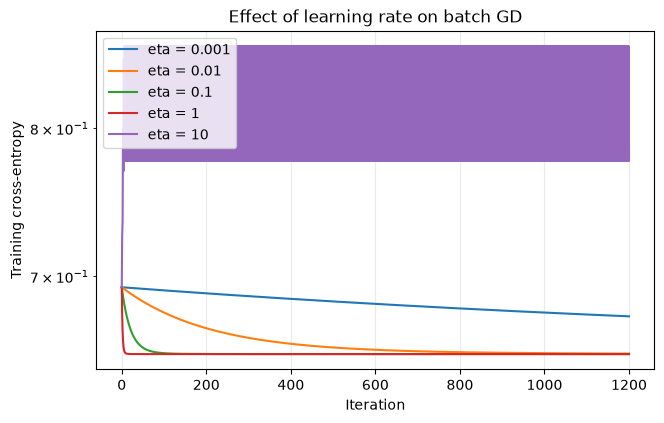

In [18]:
rng = make_rng(40)
line = random_line(rng)
X_lr, y_lr = line_data(rng, 100, line)
y_lr = y_lr.copy()
y_lr[rng.choice(len(y_lr), 40, replace=False)] *= -1
learning_rates = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
loss_curves = {}
for eta in learning_rates:
    _, history, _, _ = batch_gd(X_lr, y_lr, eta=eta,
                                max_iter=500 if FAST else 1200)
    loss_curves[eta] = history
    print(f"eta={eta:g}: first loss={history[0,1]:.6f}, final={history[-1,1]:.6f}")

plt.figure(figsize=(7.2, 4.4))
for eta, history in loss_curves.items():
    plt.plot(history[:, 0], history[:, 1], label=f"eta = {eta:g}")
plt.xlabel("Iteration")
plt.ylabel("Training cross-entropy")
plt.title("Effect of learning rate on batch GD")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.25)
save_fig("part3_3_learning_rates")
plt.show()

### Optimizer speed

For a fair comparison, we use a fixed nonseparable dataset and the same starting weights. We first find a reference minimum with L-BFGS. Then we measure the time until each method reaches a loss within $10^{-6}$ of that minimum. The SGD learning rate decreases with the epoch because a fixed rate can keep fluctuating near the optimum. We include the accuracy reached by each method along with the time.

Batch GD {'median_seconds': 0.02267014999233652, 'mean_seconds': 0.02448135699960403, 'se_seconds': 0.0007515974818117318, 'median_steps': 352.0, 'runs_reached': 100, 'runs': 100, 'largest_loss_gap': 9.72072201899099e-07}
SGD {'median_seconds': 0.0902230499923462, 'mean_seconds': 0.09363930699822959, 'se_seconds': 0.0014203156416713052, 'median_steps': 109.0, 'runs_reached': 100, 'runs': 100, 'largest_loss_gap': 9.932989375460721e-07}
L-BFGS {'median_seconds': 0.0023775000008754432, 'mean_seconds': 0.0024428409987012857, 'se_seconds': 2.4347764710583545e-05, 'median_steps': 13.0, 'runs_reached': 100, 'runs': 100, 'largest_loss_gap': 0.0}


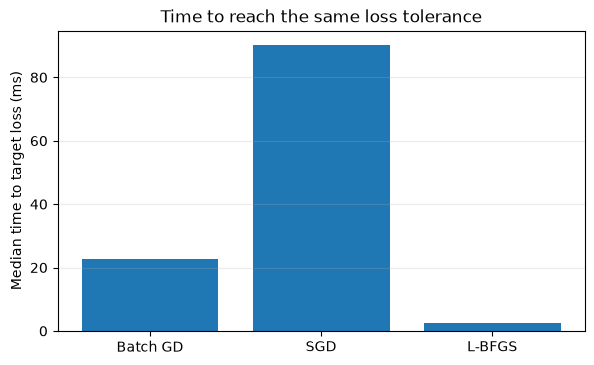

In [19]:
rng = make_rng(41)
X_speed, y_speed = line_data(rng, 100, np.array([0.1, 2.0, -1.0]))
y_speed = y_speed.copy()
y_speed[rng.choice(100, 12, replace=False)] *= -1
ref = fit_lbfgs(X_speed, y_speed, gtol=1e-12)
ref_loss = float(ref.fun)
assert ref.success or np.linalg.norm(ref.jac) < 1e-7

def timed_optimizer(method, seed):
    start = time.perf_counter()
    if method == "Batch GD":
        w, hist, steps, reached = batch_gd(
            X_speed, y_speed, eta=1.0,
            max_iter=15000 if FAST else 30000,
            target_loss=ref_loss,
        )
    elif method == "SGD":
        w, hist, steps, reached = sgd(
            X_speed, y_speed, eta=0.05, rng=np.random.default_rng(seed),
            max_epochs=1500 if FAST else 5000,
            decay=0.01, target_loss=ref_loss,
        )
    else:
        result = fit_lbfgs(X_speed, y_speed, gtol=1e-10)
        w = result.x
        steps = int(result.nit)
        reached = bool(logistic_loss(w, X_speed, y_speed) <= ref_loss + 1e-6)
    seconds = time.perf_counter() - start
    loss_gap = logistic_loss(w, X_speed, y_speed) - ref_loss
    return seconds, steps, reached, float(loss_gap)

# One warm-up is excluded from the timings.
for method in ("Batch GD", "SGD", "L-BFGS"):
    timed_optimizer(method, SEED + 500)

repeats = 5 if FAST else 100
speed_results = {}
for method in ("Batch GD", "SGD", "L-BFGS"):
    values = [timed_optimizer(method, SEED + 600 + i) for i in range(repeats)]
    times = np.array([v[0] for v in values])
    reached = np.array([v[2] for v in values])
    gaps = np.array([v[3] for v in values])
    speed_results[method] = {
        "median_seconds": float(np.median(times)),
        "mean_seconds": float(np.mean(times)),
        "se_seconds": float(np.std(times, ddof=1) / np.sqrt(len(times))),
        "median_steps": float(np.median([v[1] for v in values])),
        "runs_reached": int(reached.sum()),
        "runs": repeats,
        "largest_loss_gap": float(gaps.max()),
    }
    print(method, speed_results[method])
    assert np.all(reached), f"{method} did not reach the target tolerance"

save_json("part3_3c_speed.json", {
    "repeats": repeats, "reference_loss": ref_loss, "methods": speed_results
})

plt.figure(figsize=(6.8, 3.9))
labels = list(speed_results)
times_ms = [1000 * speed_results[k]["median_seconds"] for k in labels]
plt.bar(labels, times_ms)
plt.ylabel("Median time to target loss (ms)")
plt.title("Time to reach the same loss tolerance")
plt.grid(axis="y", alpha=0.25)
save_fig("part3_3_optimizer_time")
plt.show()

## 3.4 Separable data

When the data are linearly separable, logistic regression can keep reducing its loss by increasing the weight norm. Therefore, the unregularized problem has no finite optimal weight vector. Even so, the direction of the weights can become stable.

We train for $10^5$ iterations and track the weight norm, the loss, and the angle between $w_t$ and $w_{t+1000}$. We repeat the same experiment with an L2 penalty. Here we also penalize the bias so that all three weights remain bounded.

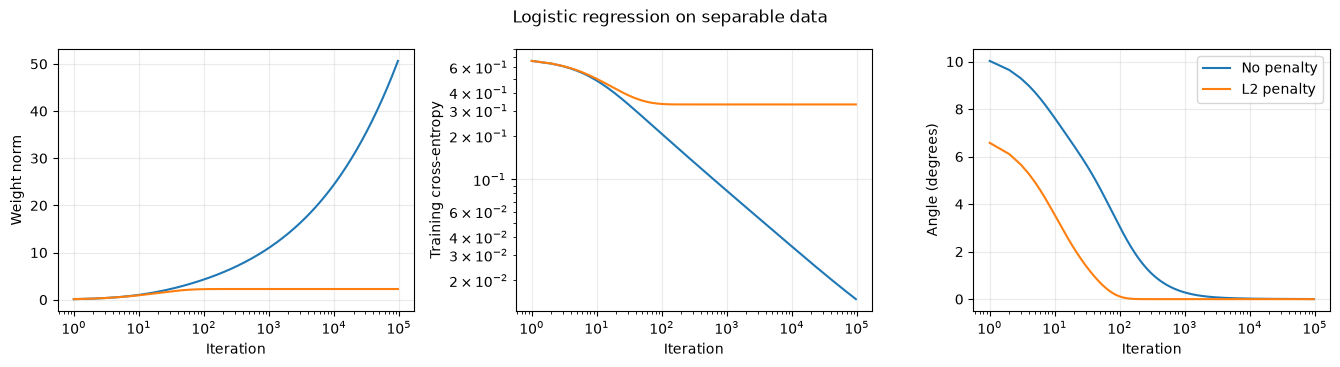

{'iterations': 100000, 'l2_lambda': 0.02, 'unregularized_final_norm': 51.213835510313295, 'l2_final_norm': 2.271623687375843, 'unregularized_final_loss': 0.014646459700533222, 'l2_final_loss': 0.33084592825313236, 'unregularized_last_angle_deg': 0.0036892264639932053, 'l2_last_angle_deg': 0.0, 'unregularized_probability_range': [9.493608088987532e-29, 1.0]}


In [20]:
rng = make_rng(60)
line = np.array([0.1, 1.8, -1.2])
X_sep, y_sep = line_data(rng, 120, line)
assert np.all(y_sep * (X_sep @ line) > 0)

iterations = 5000 if FAST else 100000
eta = 0.5
lam_sep = 0.02

# Store all three weights so we can compare t with t+1000.
def train_long_gd(lam):
    path = np.empty((iterations + 1, X_sep.shape[1]))
    path[0] = 0.0
    w = np.zeros(X_sep.shape[1])
    for t in range(1, iterations + 1):
        w -= eta * logistic_grad(w, X_sep, y_sep, lam=lam,
                                 penalize_bias=True)
        path[t] = w
    return path

path_unreg = train_long_gd(0.0)
path_l2 = train_long_gd(lam_sep)

# Plot a sample of iterations to keep the figures small.
sample_idx = np.unique(np.r_[1, np.geomspace(1, iterations, 320).astype(int)])
sample_idx = sample_idx[sample_idx + 1000 <= iterations]

def path_data(path, lam):
    w = path[sample_idx]
    w_future = path[sample_idx + 1000]
    norms = np.linalg.norm(w, axis=1)
    future_norms = np.linalg.norm(w_future, axis=1)
    cosine = np.sum(w * w_future, axis=1) / (norms * future_norms)
    angles = np.degrees(np.arccos(np.clip(cosine, -1.0, 1.0)))
    ce_loss = np.array([logistic_loss(u, X_sep, y_sep) for u in w])
    return norms, ce_loss, angles

norm0, loss0, angle0 = path_data(path_unreg, 0.0)
norm1, loss1, angle1 = path_data(path_l2, lam_sep)

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.7))
for a, values0, values1, ylabel in zip(
    ax, (norm0, loss0, angle0), (norm1, loss1, angle1),
    ("Weight norm", "Training cross-entropy", "Angle (degrees)"),
):
    a.plot(sample_idx, values0, label="No penalty")
    a.plot(sample_idx, values1, label="L2 penalty")
    a.set_xscale("log")
    a.set_xlabel("Iteration")
    a.set_ylabel(ylabel)
    a.grid(alpha=0.25)
ax[1].set_yscale("log")
ax[2].legend()
fig.suptitle("Logistic regression on separable data")
fig.tight_layout()
save_fig("part3_4_separable")
plt.show()

summary_sep = {
    "iterations": iterations, "l2_lambda": lam_sep,
    "unregularized_final_norm": float(np.linalg.norm(path_unreg[-1])),
    "l2_final_norm": float(np.linalg.norm(path_l2[-1])),
    "unregularized_final_loss": float(logistic_loss(path_unreg[-1], X_sep, y_sep)),
    "l2_final_loss": float(logistic_loss(path_l2[-1], X_sep, y_sep)),
    "unregularized_last_angle_deg": float(angle0[-1]),
    "l2_last_angle_deg": float(angle1[-1]),
    "unregularized_probability_range": [
        float(sigmoid((X_sep @ path_unreg[-1])).min()),
        float(sigmoid((X_sep @ path_unreg[-1])).max())],
}
print(summary_sep)
save_json("part3_4_separable.json", summary_sep)

## 3.5 Breast cancer

We use the breast cancer dataset to test logistic regression on real data. The original dataset labels malignant cases as 0 and benign cases as 1. We change this to $+1$ for malignant and $-1$ for benign. We use a small fixed L2 penalty ($\lambda=0.005$) because it keeps the coefficients from becoming too large on this small training set.

We first reserve 30 percent of the data for the final test. We take a validation set from the remaining training data to choose the classification threshold. Means and standard deviations are always calculated from the training subset and never from validation or test data.

In [21]:
data = load_breast_cancer()
X_raw = data.data.astype(float)
y_all = np.where(data.target == 0, 1, -1)
rng = make_rng(70)
train_pool_idx, test_idx = stratified_split(y_all, 0.30, rng)
train_idx_local, val_idx_local = stratified_split(y_all[train_pool_idx], 0.20, rng)
train_idx = train_pool_idx[train_idx_local]
val_idx = train_pool_idx[val_idx_local]
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_pool_idx) & set(test_idx)) == 0

Z_train, Z_val, mu, sd = standardize(X_raw[train_idx], X_raw[val_idx])
Z_test = (X_raw[test_idx] - mu) / sd
X_train, X_val, X_test = map(add_bias, (Z_train, Z_val, Z_test))
y_train, y_val, y_test = y_all[train_idx], y_all[val_idx], y_all[test_idx]

cancer_lam = 0.005  # Fixed in advance, before test evaluation.
cancer_result = fit_lbfgs(X_train, y_train, lam=cancer_lam, gtol=1e-10)
w_cancer = cancer_result.x
assert np.isfinite(w_cancer).all()
print("Total, training, validation, test:", len(y_all), len(y_train),
      len(y_val), len(y_test))
print("Positive label: +1 = malignant")
print("Optimization:", cancer_result.message)
print("Training cross-entropy:", logistic_loss(w_cancer, X_train, y_train))
print("L2 lambda:", cancer_lam)

Total, training, validation, test: 569 318 80 171
Positive label: +1 = malignant
Optimization: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Training cross-entropy: 0.05828391740798113
L2 lambda: 0.005


### Test results

We calculate accuracy, precision, recall, F1, the confusion matrix, ROC curve, and AUC using our own functions in `mlcore.py`. A false negative means that a malignant case was predicted as benign, so recall is especially important here.

Test accuracy: 0.976608
Test precision: 0.983871
Test recall: 0.953125
Test F1: 0.968254
Test confusion matrix, rows true [-1, +1]:
[[106   1]
 [  3  61]]
Test ROC AUC: 0.989194


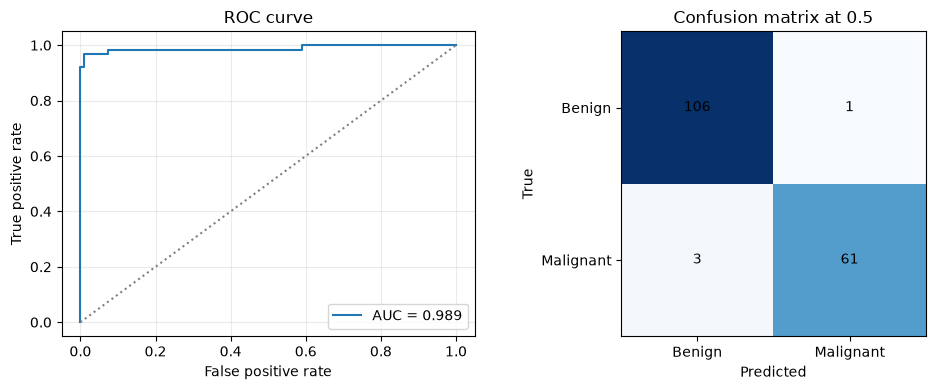

In [22]:
# We compute probabilities once on the held-out test set.
probs_test = sigmoid(X_test @ w_cancer)
pred_half = np.where(probs_test >= 0.5, 1, -1)
metrics_half = classification_metrics(y_test, pred_half)
fpr, tpr, thresholds = roc_curve(y_test, probs_test)
auc_test = auc(fpr, tpr)
print("Test accuracy:", f"{metrics_half['accuracy']:.6f}")
print("Test precision:", f"{metrics_half['precision']:.6f}")
print("Test recall:", f"{metrics_half['recall']:.6f}")
print("Test F1:", f"{metrics_half['f1']:.6f}")
print("Test confusion matrix, rows true [-1, +1]:")
print(metrics_half["confusion_matrix"])
print("Test ROC AUC:", f"{auc_test:.6f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.0))
ax[0].plot(fpr, tpr, label=f"AUC = {auc_test:.3f}")
ax[0].plot([0, 1], [0, 1], color="gray", linestyle=":")
ax[0].set_xlabel("False positive rate")
ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curve")
ax[0].legend()
ax[0].grid(alpha=0.25)
cm = metrics_half["confusion_matrix"]
ax[1].imshow(cm, cmap="Blues")
ax[1].set_xticks([0, 1], labels=["Benign", "Malignant"])
ax[1].set_yticks([0, 1], labels=["Benign", "Malignant"])
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("True")
ax[1].set_title("Confusion matrix at 0.5")
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, str(cm[i, j]), ha="center", va="center")
fig.tight_layout()
save_fig("part3_5_roc_confusion")
plt.show()

### Threshold

We select the highest probability threshold that gives malignant recall of at least $0.98$ on the validation set. We then apply this fixed threshold to the test set and compare it with $0.5$. We do not choose a threshold using test results.

Selected validation threshold: 0.159420
Validation malignant recall: 1.000000
Test precision at selected threshold: 0.885714
Test recall at selected threshold: 0.968750
Test precision at 0.5: 0.983871
Test recall at 0.5: 0.953125


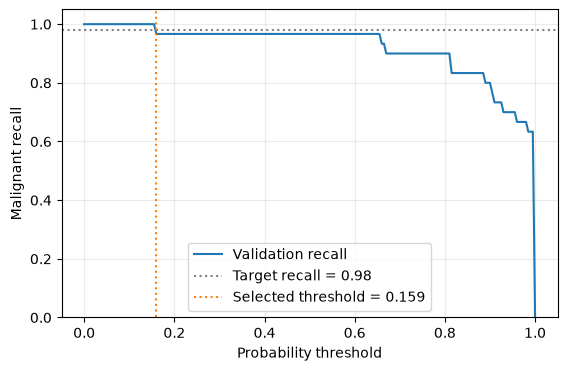

In [23]:
probs_val = sigmoid(X_val @ w_cancer)
validation_candidates = np.unique(np.r_[0.0, probs_val, 1.0])
recalled = []
for threshold in validation_candidates:
    val_pred = np.where(probs_val >= threshold, 1, -1)
    recalled.append(classification_metrics(y_val, val_pred)["recall"])
recalled = np.array(recalled)
eligible = validation_candidates[recalled >= 0.98]
assert len(eligible) > 0
selected_threshold = float(eligible.max())
val_selected = classification_metrics(y_val,
    np.where(probs_val >= selected_threshold, 1, -1))
test_selected = classification_metrics(y_test,
    np.where(probs_test >= selected_threshold, 1, -1))
print(f"Selected validation threshold: {selected_threshold:.6f}")
print(f"Validation malignant recall: {val_selected['recall']:.6f}")
print(f"Test precision at selected threshold: {test_selected['precision']:.6f}")
print(f"Test recall at selected threshold: {test_selected['recall']:.6f}")
print(f"Test precision at 0.5: {metrics_half['precision']:.6f}")
print(f"Test recall at 0.5: {metrics_half['recall']:.6f}")

val_recall_curve = [classification_metrics(
    y_val, np.where(probs_val >= t, 1, -1))["recall"]
    for t in np.linspace(0, 1, 201)]
plt.figure(figsize=(6.4, 4))
plt.plot(np.linspace(0, 1, 201), val_recall_curve,
         label="Validation recall")
plt.axhline(0.98, color="gray", linestyle=":", label="Target recall = 0.98")
plt.axvline(selected_threshold, color="tab:orange", linestyle=":",
            label=f"Selected threshold = {selected_threshold:.3f}")
plt.xlabel("Probability threshold")
plt.ylabel("Malignant recall")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.25)
save_fig("part3_5_threshold")
plt.show()

cancer_summary = {
    "data_n": len(y_all), "train_n": len(y_train),
    "validation_n": len(y_val), "test_n": len(y_test),
    "l2_lambda": cancer_lam,
    "accuracy": metrics_half["accuracy"],
    "precision_05": metrics_half["precision"],
    "recall_05": metrics_half["recall"],
    "f1_05": metrics_half["f1"],
    "test_confusion_matrix": cm.tolist(), "auc": auc_test,
    "selected_threshold": selected_threshold,
    "validation_recall_selected": val_selected["recall"],
    "test_precision_selected": test_selected["precision"],
    "test_recall_selected": test_selected["recall"],
}
save_json("part3_5_cancer.json", cancer_summary)

## 3.6 Library comparison

We first compare our unregularized model with `sklearn.linear_model.LogisticRegression` on the nonseparable synthetic data from the optimizer experiment. This is useful because unregularized logistic regression may not have a finite optimum on separable data. We then compare L2 regularization on the standardized breast cancer training data.

Our loss uses the average cross-entropy plus $\lambda\|w\|^2$, without penalizing the bias. The corresponding scikit-learn parameter is $\lambda=1/(2NC)$. We therefore set $C=1/(2N\lambda)$ for each value of $\lambda$. We compare both the coefficients and the value of our objective.

scikit-learn version: 1.9.0
Unregularized max coefficient difference: 4.440892e-16
Unregularized loss difference: 1.110223e-16
lambda=0.0005 C=3.1447: max |coef difference|=2.066e-10, |loss difference|=0.000e+00
lambda=0.005 C=0.31447: max |coef difference|=1.187e-15, |loss difference|=2.776e-17
lambda=0.05 C=0.031447: max |coef difference|=2.498e-16, |loss difference|=0.000e+00
lambda=0.5 C=0.0031447: max |coef difference|=5.551e-17, |loss difference|=0.000e+00


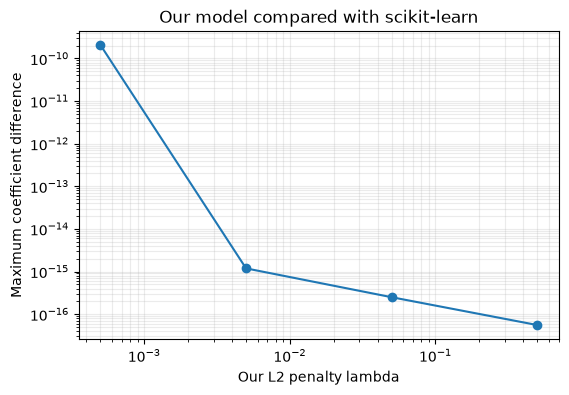

In [24]:
# Scikit-learn is used only in this library comparison section.
from sklearn.linear_model import LogisticRegression
import sklearn

N_library = len(y_train)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    sk_unreg = LogisticRegression(
        penalty=None, solver="lbfgs", fit_intercept=True,
        max_iter=5000, tol=1e-10,
    )
    sk_unreg.fit(X_speed[:, 1:], y_speed)

sk_weights = np.r_[sk_unreg.intercept_[0], sk_unreg.coef_[0]]
our_unreg = fit_lbfgs(X_speed, y_speed, gtol=1e-11)
unreg_diff = float(np.max(np.abs(our_unreg.x - sk_weights)))
unreg_loss_difference = abs(logistic_loss(our_unreg.x, X_speed, y_speed) -
                             logistic_loss(sk_weights, X_speed, y_speed))
print("scikit-learn version:", sklearn.__version__)
print("Unregularized max coefficient difference:", f"{unreg_diff:.6e}")
print("Unregularized loss difference:", f"{unreg_loss_difference:.6e}")

lambdas = [0.0005, 0.005, 0.05, 0.5]
library_rows = []
for lam in lambdas:
    C = 1.0 / (2.0 * N_library * lam)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        sk_model = LogisticRegression(
            penalty="l2", C=C, solver="lbfgs", fit_intercept=True,
            max_iter=5000, tol=1e-10,
        )
        sk_model.fit(Z_train, y_train)
    our = fit_lbfgs(X_train, y_train, lam=lam, gtol=1e-11)
    sw = np.r_[sk_model.intercept_[0], sk_model.coef_[0]]
    coef_diff = float(np.max(np.abs(our.x - sw)))
    loss_diff = float(abs(logistic_loss(our.x, X_train, y_train, lam=lam) -
                          logistic_loss(sw, X_train, y_train, lam=lam)))
    row = {"lambda": lam, "C": C, "max_coefficient_difference": coef_diff,
           "objective_difference": loss_diff}
    library_rows.append(row)
    print(f"lambda={lam:.4g} C={C:.5g}: max |coef difference|="
          f"{coef_diff:.3e}, |loss difference|={loss_diff:.3e}")

save_json("part3_6_library.json", {
    "sklearn_version": sklearn.__version__,
    "unregularized_max_coefficient_difference": unreg_diff,
    "unregularized_loss_difference": unreg_loss_difference,
    "regularized": library_rows,
})

plt.figure(figsize=(6.2, 4))
plt.loglog([r["lambda"] for r in library_rows],
           [r["max_coefficient_difference"] for r in library_rows], "o-")
plt.xlabel("Our L2 penalty lambda")
plt.ylabel("Maximum coefficient difference")
plt.title("Our model compared with scikit-learn")
plt.grid(alpha=0.25, which="both")
save_fig("part3_6_library_match")
plt.show()

## Results

We save the figures as PNG and PDF files in `figures` and the numerical summaries as JSON files in `results`. Quick-test outputs go into the `preview` subfolders, so they do not overwrite the full-run results. We use `FAST = True` for a shorter run when testing the notebook. For the final report, we use `FAST = False`, which includes 100 SGD simulations and $10^5$ iterations in the separable-data experiment. All final numbers in the report should come from that full run.

In [25]:
print("Figures saved in:", fig_dir.resolve())
print("Results saved in:", res_dir.resolve())
print("FAST =", FAST)
print("Part 3 finished.")

Figures saved in: D:\ROBT407\figures
Results saved in: D:\ROBT407\results
FAST = False
Part 3 finished.
